# Forecasting weekday AM peak demand by line

**Question:** what will weekday AM peak (07:00–08:59) boardings look like over the next quarter, line by line?

**Approach**
1. Load daily AM peak boardings for the 15 forecast lines from Snowflake (`MART.DAILY_LINE_DEMAND`).
2. Flag disruption days (line closures and big service cuts) and leave them out of training.
3. **Back-test:** train on 1 Jul 2024 – 31 Mar 2025, forecast 1 Apr – 30 Jun 2025 without looking at it, then compare with what actually happened.
4. Compare three models: a **seasonal naive** baseline, **Prophet** and **SARIMAX**. Score them with MAE, WAPE and MAPE.
5. Version 2 of Prophet and SARIMAX corrects two problems found in the first back-test (section 6). It is checked on a validation period inside training before it's used.
6. Forecast 1 Jul – 30 Sep 2025 with the average of the two best models, and write the forecast, back-test and scores back to Snowflake for Power BI.

**Data:** DTP Train Service Passenger Counts FY2024-25 (modelled estimates, CC BY 4.0), built into Snowflake marts by `sql/05_marts.sql`. Lines excluded from the forecast (Stony Point, Flemington Racecourse, City Loop short services) are set in `MART.DIM_LINE`; see `docs/data_quality_notes.md`.

## 1. Setup

Every model setting below was **fixed before looking at the test period**. If settings are tuned until the test score looks good, the test stops being a fair test. The version 2 changes in section 6 fix how the models are built; none of them is a tuned number.

In [1]:
import logging
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import snowflake.connector
from prophet import Prophet
from statsmodels.tsa.statespace.sarimax import SARIMAX

warnings.filterwarnings("ignore")  # statsmodels convergence chatter; fits are checked below
logging.getLogger("cmdstanpy").setLevel(logging.WARNING)
logging.getLogger("prophet").setLevel(logging.WARNING)
pd.set_option("display.float_format", "{:,.1f}".format)
pd.set_option("display.width", 140)

# Time split
TRAIN_START  = pd.Timestamp("2024-07-01")
TRAIN_END    = pd.Timestamp("2025-03-31")
TEST_START   = pd.Timestamp("2025-04-01")
TEST_END     = pd.Timestamp("2025-06-30")
FORECAST_END = pd.Timestamp("2025-09-30")   # 13 weeks after the data ends (step 3)

# Calendar effects found in the data (Day 4, step 1)
SUMMER_SHUTDOWN = (pd.Timestamp("2024-12-23"), pd.Timestamp("2025-01-03"))  # weekdays ran at 13-44% of a school holiday
SPECIAL_DAYS = {
    "cup_eve": "2024-11-04",                       # Monday before Melbourne Cup: 40-60% of normal
    "last_friday_before_christmas": "2024-12-20",  # about 50% of normal
}

# Disruption rule: AM peak services AND boardings both under 80% of the line's usual level
DISRUPTION_THRESHOLD = 0.8

# Model settings
PROPHET_CHANGEPOINT_PRIOR = 0.01   # conservative trend: the March peak is seasonal (check 8), not growth
PROPHET_DEFAULT_PRIOR = 0.05       # Prophet's default, shown only for comparison
SARIMAX_ORDER = (1, 0, 1)
SARIMAX_SEASONAL_ORDER = (1, 0, 1, 5)  # 5 = one working week
INTERVAL = 0.80

Importing plotly failed. Interactive plots will not work.


## 2. Load the data

One row per line per weekday, Mon–Fri from 1 Jul 2024 to 30 Sep 2025. The months after June 2025 have no passenger data yet; they hold the calendar for the forward forecast in step 3. A `LEFT JOIN` keeps days where a line had **no** AM peak data (a full closure), so they show up as gaps instead of disappearing.

The connection reuses the Snowflake CLI connection `metro`, so no password is stored in the notebook.

In [2]:
QUERY = '''
SELECT c.calendar_date      AS date,
       l.line_name          AS line,
       c.day_type,
       c.is_public_holiday,
       c.is_school_holiday,
       c.has_passenger_data,
       d.boardings,
       d.services
FROM MART.DIM_CALENDAR c
CROSS JOIN MART.DIM_LINE l
LEFT JOIN MART.DAILY_LINE_DEMAND d
       ON  d.business_date = c.calendar_date
       AND d.line_name     = l.line_name
       AND d.time_band     = 'AM Peak'
WHERE c.is_weekday
  AND l.include_in_forecast
  AND c.calendar_date <= %(end)s
ORDER BY line, date
'''

with snowflake.connector.connect(connection_name="metro") as conn:
    raw = conn.cursor().execute(QUERY, {"end": FORECAST_END.date()}).fetch_pandas_all()

df = raw.rename(columns=str.lower)
df["date"] = pd.to_datetime(df["date"])
df[["boardings", "services"]] = df[["boardings", "services"]].astype(float)

print(f"{len(df):,} rows: {df.line.nunique()} lines x {df.date.nunique()} weekdays "
      f"({df.date.min():%d %b %Y} to {df.date.max():%d %b %Y})")
print(f"Weekdays with passenger data: {df[df.has_passenger_data].date.nunique()}")

4,905 rows: 15 lines x 327 weekdays (01 Jul 2024 to 30 Sep 2025)
Weekdays with passenger data: 261


## 3. Disruption days

A **disrupted** line-day is one where the line was closed (no AM peak data), or where AM peak **services and boardings were both under 80%** of that line's usual level for the same day type. Both have to be low: a service drop with normal boardings looks like a timetable or data quirk (e.g. Mon 3 Mar 2025), not lost demand.

- "Usual" is the median for the line and day type. Public holidays and the Christmas–New Year shutdown are left out of the rule, because they're low by nature, not because of disruption.
- **Training:** disrupted days are set to missing. Both Prophet and SARIMAX can fit around gaps.
- **Test:** results are reported both with and without disrupted days.

In [3]:
has_data = df.has_passenger_data
in_summer = df.date.between(*SUMMER_SHUTDOWN)
eligible = has_data & ~df.is_public_holiday & ~in_summer

typical = (df[eligible & df.boardings.notna()]
           .groupby(["line", "day_type"])[["services", "boardings"]].median()
           .add_prefix("typical_"))
df = df.join(typical, on=["line", "day_type"])

df["is_closed"] = has_data & df.boardings.isna()
df["is_low_service"] = (eligible
                        & (df.services < DISRUPTION_THRESHOLD * df.typical_services)
                        & (df.boardings < DISRUPTION_THRESHOLD * df.typical_boardings))
df["is_disrupted"] = df.is_closed | df.is_low_service

df["period"] = np.select(
    [df.date <= TRAIN_END, df.date <= TEST_END],
    ["train", "test"], default="forecast")

summary = (df[has_data].groupby("period", sort=False)
           .agg(line_days=("line", "size"), closed=("is_closed", "sum"),
                low_service=("is_low_service", "sum"), disrupted=("is_disrupted", "sum")))
summary["disrupted_pct"] = 100 * summary.disrupted / summary.line_days
summary

,line_days,closed,low_service,disrupted,disrupted_pct
period,,,,,
train,2940,7,32,39,1.3
test,975,7,7,14,1.4


In [4]:
# The disrupted line-days in the test period
(df[(df.period == "test") & df.is_disrupted]
   .assign(day=lambda x: x.date.dt.strftime("%a %d %b"),
           boardings_vs_usual=lambda x: x.boardings / x.typical_boardings)
   [["day", "line", "day_type", "is_closed", "boardings", "typical_boardings", "boardings_vs_usual"]]
   .reset_index(drop=True))

,day,line,day_type,is_closed,boardings,typical_boardings,boardings_vs_usual
0,Mon 14 Apr,Cranbourne,School Holiday,False,"2,790.0","9,950.0",0.3
1,Tue 15 Apr,Cranbourne,School Holiday,False,"2,820.0","9,950.0",0.3
2,Thu 17 Apr,Cranbourne,School Holiday,False,"2,200.0","9,950.0",0.2
3,Mon 07 Apr,Glen Waverley,School Holiday,True,NaN,"8,200.0",NaN
4,Tue 08 Apr,Glen Waverley,School Holiday,True,NaN,"8,200.0",NaN
5,Wed 09 Apr,Glen Waverley,School Holiday,True,NaN,"8,200.0",NaN
6,Thu 10 Apr,Glen Waverley,School Holiday,True,NaN,"8,200.0",NaN
7,Mon 26 May,Mernda,Normal Weekday,False,"8,490.0","18,830.0",0.5
8,Mon 14 Apr,Pakenham,School Holiday,False,"3,420.0","15,105.0",0.2
9,Tue 15 Apr,Pakenham,School Holiday,False,"3,530.0","15,105.0",0.2


## 4. Calendar features

These are the calendar effects found when exploring the data (step 1). Each one is a column the models can use.

| Feature | Days | Why |
|---|---|---|
| `public_holiday` | Victorian public holidays | **One shared effect.** None of the four test-period holidays (Good Friday, Easter Monday, ANZAC Day, King's Birthday) appears in training, so the models can't learn a separate effect for each holiday. Version 2 excludes the Christmas-period holidays from this effect (section 6) |
| `school_holiday` | School holiday weekdays that aren't public holidays | AM peak runs about 27% lower |
| `summer_shutdown` | 23 Dec 2024 – 3 Jan 2025 | Far quieter than an ordinary school holiday |
| `cup_eve`, `last_friday_before_christmas` | 4 Nov 2024, 20 Dec 2024 | One-off quiet days. Without these, the models would learn them as noise |

**Known miss:** Tue–Thu 22–24 April 2025 fall between Easter Monday and ANZAC Day and ran about 26% below a normal week. Nothing like that happens in training, so it's deliberately left unmodelled.

In [5]:
cal = df[["date", "is_public_holiday", "is_school_holiday"]].drop_duplicates("date").sort_values("date")
cal["public_holiday"] = cal.is_public_holiday.astype(int)
cal["school_holiday"] = (cal.is_school_holiday & ~cal.is_public_holiday).astype(int)
cal["summer_shutdown"] = cal.date.between(*SUMMER_SHUTDOWN).astype(int)
for name, day in SPECIAL_DAYS.items():
    cal[name] = (cal.date == pd.Timestamp(day)).astype(int)
EXOG = ["public_holiday", "school_holiday", "summer_shutdown", *SPECIAL_DAYS]

# Model input: one row per line per weekday. y = AM peak boardings, missing where disrupted or closed.
data = df.merge(cal[["date", *EXOG]], on="date").rename(columns={"date": "ds"})
data["actual"] = data.boardings
data["y"] = data.boardings.where(~data.is_disrupted)


# Holiday days the models face in the test and forecast periods
ahead = cal[cal.date.between(TEST_START, FORECAST_END)]
ahead.groupby(np.where(ahead.date <= TEST_END, "1 test", "2 forecast"))[
    ["public_holiday", "school_holiday"]].sum().rename_axis("period")

,public_holiday,school_holiday
period,,
1 test,4,9
2 forecast,1,16


## 5. A first look

Network AM peak boardings (the 15 lines added together) on each weekday. The dashed line marks the end of training: everything to its right is hidden from the models.

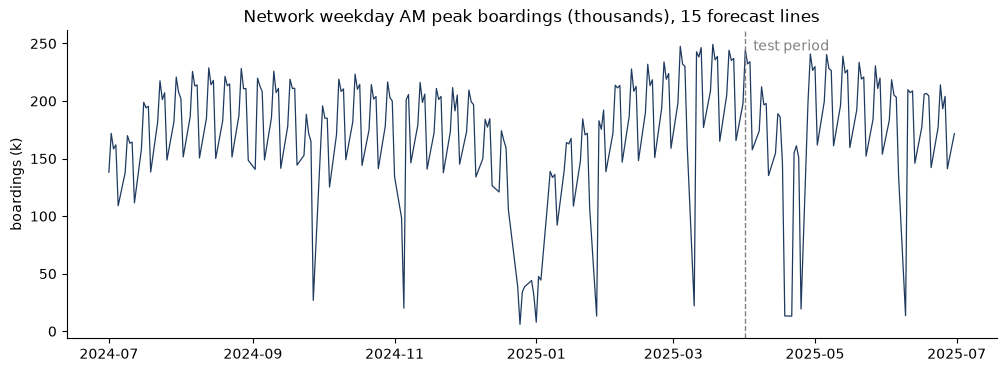

In [6]:
network = data[data.ds <= TEST_END].groupby("ds").agg(actual=("actual", "sum"),
                                                     disrupted=("is_disrupted", "sum"))
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(network.index, network.actual / 1000, lw=0.9, color="#1f3a5f")
ax.axvline(TEST_START, color="grey", ls="--", lw=1)
ax.text(TEST_START, ax.get_ylim()[1] * 0.97, "  test period", va="top", color="grey")
ax.set(title="Network weekday AM peak boardings (thousands), 15 forecast lines", ylabel="boardings (k)")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## 6. The models, and why there are two versions

- **Seasonal naive (baseline):** for each test day, predict the line's **last known value for the same weekday** before the forecast starts. Every Tuesday in April–June is predicted as the line's last Tuesday in March. It sees no data after the cut-off, so it plays by the same rules as the other models. A model that can't beat it isn't adding anything.
- **Prophet:** trend + weekly pattern + the calendar features, with a **conservative trend** (changepoint prior 0.01), because the March peak is a recurring seasonal high, not growth to carry forward. Prophet's default setting (0.05) is fitted alongside for comparison only.
- **SARIMAX:** a classical time-series model: ARMA(1,1) with a weekly (5-day) seasonal ARMA(1,1), a constant, and the calendar features as inputs.

Every model forecasts the whole period in one go from the cut-off date, the way a real quarterly forecast would be made.

**Version 1 → version 2.** The first back-test (version 1, kept below for transparency) showed two problems with how the models were built:
1. **Additive holiday effects.** Version 1 learned a holiday as "about 180k fewer passengers". On a Friday, which already starts lower, that gave **negative** forecasts for Good Friday and ANZAC Day.
2. **SARIMAX lost the weekly pattern.** Its seasonal part fades out over a long forecast, so by May it predicted almost the same value for every day of the week.

Version 2 fixes how the models are built. Nothing in it was tuned to the test results:

| Change | Version 1 | Version 2 |
|---|---|---|
| Scale | Boardings | **Log of boardings**, so every effect is a percentage. A public holiday becomes "about 10% of a normal day" and a Friday "about 80%"; together that's about 8%. A log-scale forecast can never be negative |
| Public holidays | One effect for all | One shared effect for holidays **outside** the Christmas–New Year shutdown. Christmas Day, Boxing Day and New Year's Day (3–17% of normal) get their own day effects in the shutdown window |
| SARIMAX weekly pattern | Seasonal ARMA only | Plus a **fixed effect for each day of the week**, like Prophet's weekly pattern, and a Christmas Day / New Year's Day flag |
| Negative forecasts | Possible | Impossible (floored at zero) |

**SARIMAX fitting (both versions).** If the default optimiser stops before converging, the fit is retried with more iterations and then with a different optimiser (Powell). This was added after the first full run showed three lines stopping early. Section 11 shows what changed.

To avoid choosing version 2 because it scores well on the test period, it's first checked on a **validation period inside the training data** (section 7). The rule, set in advance: **version 2 is used if its WAPE on validation is no worse than version 1's.**

In [7]:
logging.getLogger("cmdstanpy").disabled = True   # hide "Chain [1] start/done processing" lines

# Version 2 calendar columns
cal["public_holiday_v2"] = (cal.is_public_holiday & ~cal.date.between(*SUMMER_SHUTDOWN)).astype(int)
cal["christmas_newyear"] = cal.date.isin(pd.to_datetime(["2024-12-25", "2025-01-01"])).astype(int)
for i, d in enumerate(["tue", "wed", "thu", "fri"], start=1):      # Monday is the base day
    cal[d] = (cal.date.dt.dayofweek == i).astype(int)

EXOG_BY_VERSION = {
    "v1": ["public_holiday", "school_holiday", "summer_shutdown", *SPECIAL_DAYS],
    "v2": ["public_holiday_v2", "christmas_newyear", "school_holiday", "summer_shutdown",
           *SPECIAL_DAYS, "tue", "wed", "thu", "fri"],
}
data = data.merge(cal[["date", "public_holiday_v2", "christmas_newyear", "tue", "wed", "thu", "fri"]]
                  .rename(columns={"date": "ds"}), on="ds")


def prophet_holidays(version):
    ph = cal.loc[cal.is_public_holiday, "date"]
    if version == "v2":
        ph = ph[~ph.between(*SUMMER_SHUTDOWN)]   # Christmas-period holidays use the shutdown window instead
    return pd.concat([
        pd.DataFrame({"holiday": "public_holiday", "ds": ph}),
        pd.DataFrame({"holiday": "summer_shutdown", "ds": [SUMMER_SHUTDOWN[0]],
                      "upper_window": [(SUMMER_SHUTDOWN[1] - SUMMER_SHUTDOWN[0]).days]}),
        pd.DataFrame({"holiday": list(SPECIAL_DAYS), "ds": pd.to_datetime(list(SPECIAL_DAYS.values()))}),
    ]).reindex(columns=["holiday", "ds", "lower_window", "upper_window"]).fillna(
        {"lower_window": 0, "upper_window": 0}).astype({"lower_window": int, "upper_window": int})

HOLIDAYS = {v: prophet_holidays(v) for v in ("v1", "v2")}


def seasonal_naive(train, future):
    # Last known (non-missing) value for each weekday in training, repeated forward.
    known = train.dropna(subset=["y"])
    last = known.groupby(known.ds.dt.dayofweek).y.last()
    return future.ds.dt.dayofweek.map(last).to_numpy()


def prophet_forecast(train, future, version, changepoint_prior=PROPHET_CHANGEPOINT_PRIOR):
    # Returns an (n, 3) array: forecast, lower, upper.
    t = train[["ds", "y", "school_holiday"]].copy()
    if version == "v2":
        t["y"] = np.log1p(t.y)               # log(1 + y), so zero boardings still work
    m = Prophet(growth="linear", weekly_seasonality=True, yearly_seasonality=False,
                daily_seasonality=False, holidays=HOLIDAYS[version],
                changepoint_prior_scale=changepoint_prior, interval_width=INTERVAL)
    m.add_regressor("school_holiday")
    m.fit(t)
    out = m.predict(future[["ds", "school_holiday"]])[["yhat", "yhat_lower", "yhat_upper"]].to_numpy()
    return np.clip(np.expm1(out), 0, None) if version == "v2" else out


def sarimax_forecast(train, future, version, robust=False):
    # Returns (n, 3) array (forecast, lower, upper), whether the fit converged, and the fit method.
    # robust=True: if the default fit doesn't converge, retry with more iterations, then Powell.
    cols = EXOG_BY_VERSION[version]
    y = train.y.to_numpy(dtype=float)
    if version == "v2":
        y = np.log1p(y)
    model = SARIMAX(y, exog=train[cols].to_numpy(dtype=float), order=SARIMAX_ORDER,
                    seasonal_order=SARIMAX_SEASONAL_ORDER, trend="c")
    res, method = model.fit(disp=False, maxiter=500), "lbfgs"
    if robust and not res.mle_retvals.get("converged", True):
        res, method = model.fit(disp=False, maxiter=3000), "lbfgs, 3000 iterations"
        if not res.mle_retvals.get("converged", True):
            res, method = model.fit(disp=False, method="powell", maxiter=10000), "powell"
    fc = res.get_forecast(steps=len(future), exog=future[cols].to_numpy(dtype=float))
    out = np.column_stack([fc.predicted_mean, fc.conf_int(alpha=1 - INTERVAL)])
    if version == "v2":
        out = np.clip(np.expm1(out), 0, None)
    return out, res.mle_retvals.get("converged", True), method


def run_split(train_start, train_end, test_start, test_end):
    # Fit every model on [train_start, train_end] for each line; forecast [test_start, test_end].
    rows, fits = [], []
    for line, g in data.groupby("line"):
        train = g[g.ds.between(train_start, train_end)].sort_values("ds")
        test = g[g.ds.between(test_start, test_end)].sort_values("ds")
        out = test[["ds", "line", "day_type", "actual", "is_disrupted"]].copy()
        out["seasonal_naive"] = seasonal_naive(train, test)
        for v in ("v1", "v2"):
            p = prophet_forecast(train, test, v)
            s, converged, method = sarimax_forecast(train, test, v, robust=True)
            for name, arr in (("prophet", p), ("sarimax", s)):
                out[f"{name}_{v}"], out[f"{name}_{v}_lower"], out[f"{name}_{v}_upper"] = arr.T
            fits.append({"line": line, "version": v, "sarimax_converged": converged, "method": method})
        out["prophet_v2_default_trend"] = prophet_forecast(train, test, "v2", PROPHET_DEFAULT_PRIOR)[:, 0]
        rows.append(out)
    return pd.concat(rows, ignore_index=True), pd.DataFrame(fits)


def add_ensemble(frame):
    # Average of Prophet v1 (floored at zero) and SARIMAX v2; interval = average of the two bounds.
    for suffix in ("", "_lower", "_upper"):
        frame[f"ensemble{suffix}"] = (frame[f"prophet_v1{suffix}"].clip(lower=0) + frame[f"sarimax_v2{suffix}"]) / 2
    return frame

## 7. Validation inside the training period: version 1 vs version 2

Train on 1 Jul 2024 – 31 Jan 2025 and forecast 3 Feb – 31 Mar 2025 (including Labour Day). The test period (April–June) is still untouched at this point.

**Scores used:**
- **MAE** (mean absolute error): the average miss, in boardings per line per day.
- **WAPE** (weighted absolute percentage error): total miss ÷ total boardings. This is the **headline % score**, because it isn't thrown off by tiny values.
- **MAPE** (mean absolute percentage error): the average % miss per day. It's easy to explain, but it explodes on public holidays, when quiet lines carry only 10–60 AM peak passengers, so it's shown by day type.

All scores **exclude disrupted days**, because no model can foresee a line closure.

In [8]:
MODELS = {
    "seasonal_naive": "Seasonal naive (baseline)",
    "ensemble": "Ensemble: average of Prophet v1 + SARIMAX v2",
    "prophet_v2": "Prophet v2",
    "sarimax_v2": "SARIMAX v2",
    "prophet_v1": "Prophet v1 (first run)",
    "sarimax_v1": "SARIMAX v1 (first run)",
    "prophet_v2_default_trend": "Prophet v2, default trend (comparison only)",
}


def score(frame, models=MODELS):
    f = frame[frame.actual.notna()]
    rows = {}
    for col, label in models.items():
        err = (f[col] - f.actual).abs()
        nz = f.actual > 0
        rows[label] = {"MAE": err.mean(), "WAPE %": 100 * err.sum() / f.actual.sum(),
                       "MAPE %": 100 * (err[nz] / f.actual[nz]).mean(), "line-days": len(f)}
    return pd.DataFrame(rows).T


VAL_TRAIN_END, VAL_START, VAL_END = pd.Timestamp("2025-01-31"), pd.Timestamp("2025-02-03"), TRAIN_END
validation, val_fits = run_split(TRAIN_START, VAL_TRAIN_END, VAL_START, VAL_END)
validation = add_ensemble(validation)
val_scores = score(validation[~validation.is_disrupted])

decision = {}
for m in ("prophet", "sarimax"):
    v1, v2 = (val_scores.loc[MODELS[f"{m}_{v}"], "WAPE %"] for v in ("v1", "v2"))
    decision[m] = "v2" if v2 <= v1 else "v1"
    print(f"{m}: validation WAPE v1 {v1:.1f}% vs v2 {v2:.1f}% -> use {decision[m]}")
val_scores

prophet: validation WAPE v1 16.3% vs v2 22.2% -> use v1
sarimax: validation WAPE v1 33.3% vs v2 17.4% -> use v2


,MAE,WAPE %,MAPE %,line-days
Seasonal naive (baseline),"4,532.7",33.4,33.9,614.0
Ensemble: average of Prophet v1 + SARIMAX v2,"2,281.6",16.8,17.0,614.0
Prophet v2,"3,016.7",22.2,21.3,614.0
SARIMAX v2,"2,366.4",17.4,16.5,614.0
Prophet v1 (first run),"2,220.5",16.3,18.3,614.0
SARIMAX v1 (first run),"4,522.4",33.3,76.2,614.0
"Prophet v2, default trend (comparison only)","2,265.2",16.7,15.5,614.0


## 8. Back-test on the test period (1 Apr – 30 Jun 2025)

Train on 1 Jul 2024 – 31 Mar 2025 and forecast the 13 test weeks in one go. Version 1 is shown alongside, unchanged from the first run.

In [9]:
backtest, fits = run_split(TRAIN_START, TRAIN_END, TEST_START, TEST_END)
backtest = add_ensemble(backtest)
clean = backtest[~backtest.is_disrupted]
print(f"Back-test: {len(backtest):,} line-days, {backtest.line.nunique()} lines, "
      f"{backtest.is_disrupted.sum()} disrupted line-days excluded from scoring")
print("SARIMAX converged:", fits.groupby("version").sarimax_converged.sum().to_dict(), "of 15 lines;",
      "refitted with more iterations or Powell:", fits[fits.method != "lbfgs"][["line", "version", "method"]]
      .apply(lambda r: f"{r.line} ({r.version}, {r.method})", axis=1).tolist())
print("\nAll 15 lines, excluding disrupted days")
score(clean)

Back-test: 975 line-days, 15 lines, 14 disrupted line-days excluded from scoring
SARIMAX converged: {'v1': 15, 'v2': 15} of 15 lines; refitted with more iterations or Powell: ['Cranbourne (v2, lbfgs, 3000 iterations)', 'Mernda (v2, powell)', 'Pakenham (v2, powell)']

All 15 lines, excluding disrupted days


,MAE,WAPE %,MAPE %,line-days
Seasonal naive (baseline),"2,259.3",18.3,290.9,961.0
Ensemble: average of Prophet v1 + SARIMAX v2,"1,303.8",10.5,19.9,961.0
Prophet v2,"4,053.1",32.8,36.4,961.0
SARIMAX v2,"1,220.7",9.9,13.4,961.0
Prophet v1 (first run),"1,454.2",11.8,33.9,961.0
SARIMAX v1 (first run),"4,075.2",32.9,252.6,961.0
"Prophet v2, default trend (comparison only)","4,832.7",39.1,42.6,961.0


In [10]:
# By type of day: MAPE %, and WAPE % in brackets for the headline models
day_groups = {
    "Normal weekdays": clean[clean.day_type == "Normal Weekday"],
    "School holidays": clean[clean.day_type == "School Holiday"],
    "Public holidays": clean[clean.day_type == "Public Holiday"],
    "All days, INCLUDING disrupted": backtest,
}
by_day_type = pd.concat({name: score(frame) for name, frame in day_groups.items()})
print("WAPE % by type of day")
display(by_day_type["WAPE %"].unstack().round(1))
print("MAPE % by type of day")
by_day_type["MAPE %"].unstack().round(1)

WAPE % by type of day


,Seasonal naive (baseline),Ensemble: average of Prophet v1 + SARIMAX v2,Prophet v2,SARIMAX v2,Prophet v1 (first run),SARIMAX v1 (first run),"Prophet v2, default trend (comparison only)"
Normal weekdays,12.3,9.8,36.1,9.4,10.6,20.9,43.3
School holidays,15.7,13.5,9.6,12.1,15.0,63.1,10.3
Public holidays,"1,125.6",64.4,61.9,37.8,125.7,"1,310.1",68.9
"All days, INCLUDING disrupted",19.1,11.1,33.6,10.5,12.3,34.0,39.9


MAPE % by type of day


,Seasonal naive (baseline),Ensemble: average of Prophet v1 + SARIMAX v2,Prophet v2,SARIMAX v2,Prophet v1 (first run),SARIMAX v1 (first run),"Prophet v2, default trend (comparison only)"
Normal weekdays,12.8,10.3,36.5,9.9,11.2,19.3,43.2
School holidays,16.4,13.2,9.9,12.1,14.5,64.6,10.8
Public holidays,"4,459.5",157.3,89.7,60.6,368.4,"3,663.6",98.5
"All days, INCLUDING disrupted",292.2,22.1,39.4,15.7,35.9,255.4,45.8


In [11]:
# Network level: add up the 15 lines each day, then score. This is the number a planner sees first.
net = clean.groupby("ds")[["actual", *MODELS]].sum()
print("Network total (15 lines), excluding disrupted line-days")
score(net.assign(is_disrupted=False))

Network total (15 lines), excluding disrupted line-days


,MAE,WAPE %,MAPE %,line-days
Seasonal naive (baseline),"29,553.1",16.2,82.6,65.0
Ensemble: average of Prophet v1 + SARIMAX v2,"14,701.0",8.0,11.8,65.0
Prophet v2,"54,948.8",30.0,32.8,65.0
SARIMAX v2,"13,292.6",7.3,9.6,65.0
Prophet v1 (first run),"16,537.9",9.0,16.0,65.0
SARIMAX v1 (first run),"59,378.6",32.5,107.3,65.0
"Prophet v2, default trend (comparison only)","69,913.3",38.2,41.1,65.0


In [12]:
# By line, version 2: MAE and WAPE, and whether each model beats the baseline on MAE.
headline = {"seasonal_naive": MODELS["seasonal_naive"], "prophet_v2": MODELS["prophet_v2"],
            "sarimax_v2": MODELS["sarimax_v2"]}
rows = {}
for line, g in clean.groupby("line"):
    s = score(g, headline)
    rows[line] = {f"{short} {k}": s.loc[label, k]
                  for short, label in zip(["naive", "prophet", "sarimax"], headline.values())
                  for k in ("MAE", "WAPE %")}
per_line = pd.DataFrame(rows).T
per_line["prophet beats baseline"] = per_line["prophet MAE"] < per_line["naive MAE"]
per_line["sarimax beats baseline"] = per_line["sarimax MAE"] < per_line["naive MAE"]
# Bias: average forecast minus actual, as % of actual (+ = over-forecast)
per_line["prophet bias %"] = clean.groupby("line").apply(
    lambda g: 100 * (g.prophet_v2.sum() / g.actual.sum() - 1))
per_line["avg actual"] = clean.groupby("line").actual.mean()
per_line = per_line.sort_values("avg actual", ascending=False)
print(f"Prophet v2 beats the baseline on {per_line['prophet beats baseline'].sum()} of {len(per_line)} lines; "
      f"SARIMAX v2 on {per_line['sarimax beats baseline'].sum()}")
per_line.round(1)

Prophet v2 beats the baseline on 2 of 15 lines; SARIMAX v2 on 15


,naive MAE,naive WAPE %,prophet MAE,prophet WAPE %,sarimax MAE,sarimax WAPE %,prophet beats baseline,sarimax beats baseline,prophet bias %,avg actual
Pakenham,"3,866.0",21.3,"8,674.2",47.7,"1,874.0",10.3,False,True,47.0,"18,186.9"
Lilydale,"3,724.2",21.0,"6,083.1",34.3,"1,793.5",10.1,False,True,32.9,"17,739.4"
Mernda,"3,330.3",19.5,"7,026.8",41.1,"1,433.5",8.4,False,True,40.9,"17,108.6"
Frankston,"2,684.3",16.6,"2,250.7",13.9,"1,516.8",9.4,True,True,10.6,"16,208.9"
Werribee,"2,595.8",16.8,"4,248.5",27.6,"1,367.0",8.9,False,True,26.4,"15,408.9"
Craigieburn,"2,440.3",15.9,"4,707.3",30.7,"1,527.0",9.9,False,True,30.2,"15,347.1"
Hurstbridge,"2,498.8",17.6,"2,686.0",18.9,"2,280.5",16.0,False,True,-16.5,"14,222.3"
Sunbury,"2,680.0",19.3,"5,060.4",36.5,"1,240.9",8.9,False,True,36.3,"13,874.8"
Cranbourne,"2,331.3",19.8,"6,570.3",55.7,"1,185.8",10.1,False,True,55.6,"11,795.5"
Belgrave,"1,613.8",14.7,"3,606.2",33.0,825.8,7.5,False,True,32.4,"10,942.6"


In [13]:
# Do the 80% intervals hold about 80% of actual values?
for m in ("prophet_v1", "prophet_v2", "sarimax_v1", "sarimax_v2", "ensemble"):
    inside = clean.actual.between(clean[f"{m}_lower"], clean[f"{m}_upper"])
    print(f"{MODELS[m][:30]:<32} {100 * inside.mean():.0f}% of actual values inside the 80% interval")

Prophet v1 (first run)           58% of actual values inside the 80% interval
Prophet v2                       22% of actual values inside the 80% interval
SARIMAX v1 (first run)           84% of actual values inside the 80% interval
SARIMAX v2                       85% of actual values inside the 80% interval
Ensemble: average of Prophet v   79% of actual values inside the 80% interval


## 9. Public holidays and the Easter–ANZAC working days

The four test-period holidays, network total: version 1 vs version 2.

In [14]:
holiday_names = {"2025-04-18": "Good Friday", "2025-04-21": "Easter Monday",
                 "2025-04-25": "ANZAC Day", "2025-06-09": "King's Birthday"}
ph = net.loc[pd.to_datetime(list(holiday_names)), ["actual", "seasonal_naive", "prophet_v1", "prophet_v2",
                                                     "sarimax_v1", "sarimax_v2", "ensemble"]]
ph.index = [f"{holiday_names[d.strftime('%Y-%m-%d')]} ({d:%a %d %b})" for d in ph.index]
ph.round(0)

,actual,seasonal_naive,prophet_v1,prophet_v2,sarimax_v1,sarimax_v2,ensemble
Good Friday (Fri 18 Apr),"13,280.0","165,640.0","-3,864.0","20,175.0","208,734.0","17,548.0","9,574.0"
Easter Monday (Mon 21 Apr),"13,170.0","197,800.0","26,883.0","24,247.0","212,462.0","21,061.0","24,004.0"
ANZAC Day (Fri 25 Apr),"19,330.0","165,640.0","-3,293.0","20,629.0","207,398.0","17,510.0","9,734.0"
King's Birthday (Mon 09 Jun),"13,530.0","197,800.0","30,879.0","28,372.0","207,718.0","20,967.0","26,147.0"


In [15]:
# The known miss: the three working days between Easter Monday and ANZAC Day.
bridge = net.loc["2025-04-22":"2025-04-24", ["actual", "seasonal_naive", "prophet_v1", "sarimax_v2", "ensemble"]]
bridge.assign(ensemble_error_pct=100 * (bridge.ensemble / bridge.actual - 1)).round(0)

,actual,seasonal_naive,prophet_v1,sarimax_v2,ensemble,ensemble_error_pct
ds,,,,,,
2025-04-22,"154,830.0","244,130.0","230,726.0","232,120.0","231,423.0",49.0
2025-04-23,"161,130.0","235,170.0","218,613.0","220,828.0","219,721.0",36.0
2025-04-24,"150,920.0","237,040.0","220,762.0","222,177.0","221,470.0",47.0


## 11. Model choice for the forward forecast

| Model | Validation WAPE (Feb–Mar) | Test WAPE (Apr–Jun) |
|---|---|---|
| Prophet v1 | **16.3%** (best) | 11.8% |
| SARIMAX v2 | 17.4% | **9.9%** (best) |

Validation ranks Prophet first and the test ranks SARIMAX first, so neither is consistently better. Picking SARIMAX because it won the test would mean choosing on the test result. The forward forecast therefore uses the **ensemble: the average of the two models**, a standard way to hedge between two models of similar skill.

- Prophet v1's forecast is floored at zero first, so its additive holiday effect can't go negative.
- The ensemble's 80% interval is the average of the two models' bounds. That's an approximation, not a formal interval.

**SARIMAX convergence check.** In the first full run, SARIMAX v2 stopped before converging on three lines, and those unconverged fits were what the back-test scored. The back-test above now uses converged fits (section 6). The table compares the two, so the change is visible: the converged fits moved each forecast by 5–15% and lowered the error on all three lines.

In [16]:
check = []
for _, r in fits[(fits.version == "v2") & (fits.method != "lbfgs")].iterrows():
    g = data[data.line == r.line]
    train = g[g.ds.between(TRAIN_START, TRAIN_END)].sort_values("ds")
    test = g[g.ds.between(TEST_START, TEST_END)].sort_values("ds")
    default_fit, default_converged, _ = sarimax_forecast(train, test, "v2", robust=False)
    used = backtest.loc[backtest.line == r.line].sort_values("ds")
    keep = ~used.is_disrupted.to_numpy() & used.actual.notna().to_numpy()
    actual = used.actual.to_numpy()[keep]
    wape = lambda pred: 100 * np.abs(pred[keep] - actual).sum() / actual.sum()
    check.append({"line": r.line, "converged fit method": r.method, "default fit converged": default_converged,
                  "avg change in forecast %": 100 * np.mean(np.abs(used.sarimax_v2.to_numpy() / default_fit[:, 0] - 1)),
                  "test WAPE % default fit": wape(default_fit[:, 0]),
                  "test WAPE % converged fit": wape(used.sarimax_v2.to_numpy())})
pd.DataFrame(check).set_index("line").round(2)

,converged fit method,default fit converged,avg change in forecast %,test WAPE % default fit,test WAPE % converged fit
line,,,,,
Cranbourne,"lbfgs, 3000 iterations",False,4.5,13.4,10.1
Mernda,powell,False,6.1,13.3,8.4
Pakenham,powell,False,14.6,14.4,10.3


## 12. Forward forecast: 1 Jul – 30 Sep 2025

Both models are refitted on the **full year** (1 Jul 2024 – 30 Jun 2025) and forecast the next 66 weekdays in one go. The calendar for this period holds two school holiday breaks (7–18 Jul and 22 Sep onwards) and one public holiday (the AFL Grand Final eve, Fri 26 Sep).

In [17]:
FC_START = TEST_END + pd.Timedelta(days=1)
rows, fc_fits = [], []
for line, g in data.groupby("line"):
    train = g[g.ds.between(TRAIN_START, TEST_END)].sort_values("ds")
    future = g[g.ds.between(FC_START, FORECAST_END)].sort_values("ds")
    out = future[["ds", "line", "day_type"]].copy()
    p = np.clip(prophet_forecast(train, future, "v1"), 0, None)
    s, converged, method = sarimax_forecast(train, future, "v2", robust=True)
    out["prophet_v1"], out["prophet_v1_lower"], out["prophet_v1_upper"] = p.T
    out["sarimax_v2"], out["sarimax_v2_lower"], out["sarimax_v2_upper"] = s.T
    rows.append(add_ensemble(out))
    fc_fits.append({"line": line, "sarimax_converged": converged, "method": method})

forecast = pd.concat(rows, ignore_index=True)
fc_fits = pd.DataFrame(fc_fits)
print(f"Forecast: {len(forecast):,} line-days ({forecast.ds.nunique()} weekdays x {forecast.line.nunique()} lines)")
print(f"SARIMAX converged on {fc_fits.sarimax_converged.sum()} of 15 lines; methods used: "
      f"{fc_fits.method.value_counts().to_dict()}")

Forecast: 990 line-days (66 weekdays x 15 lines)
SARIMAX converged on 15 of 15 lines; methods used: {'lbfgs': 13, 'powell': 2}


In [18]:
# Per line: average normal-weekday AM peak, last quarter (actual) vs next quarter (ensemble forecast)
last_q = (data[data.ds.between(TEST_START, TEST_END) & (data.day_type == "Normal Weekday") & data.y.notna()]
          .groupby("line").y.mean().rename("Apr-Jun actual"))
next_q = (forecast[forecast.day_type == "Normal Weekday"].groupby("line")
          .agg(**{"Jul-Sep forecast": ("ensemble", "mean"),
                  "80% low": ("ensemble_lower", "mean"), "80% high": ("ensemble_upper", "mean")}))
outlook = pd.concat([last_q, next_q], axis=1)
outlook["change %"] = 100 * (outlook["Jul-Sep forecast"] / outlook["Apr-Jun actual"] - 1)
outlook.loc["Network (15 lines)"] = outlook.sum().where(outlook.columns != "change %")
outlook.loc["Network (15 lines)", "change %"] = 100 * (
    outlook.loc["Network (15 lines)", "Jul-Sep forecast"] / outlook.loc["Network (15 lines)", "Apr-Jun actual"] - 1)
print("Average normal-weekday AM peak boardings")
outlook.sort_values("Apr-Jun actual", ascending=False).round(0)

Average normal-weekday AM peak boardings


,Apr-Jun actual,Jul-Sep forecast,80% low,80% high,change %
line,,,,,
Network (15 lines),"197,644.0","197,024.0","166,955.0","231,385.0",-0.0
Pakenham,"19,311.0","18,983.0","15,748.0","22,729.0",-2.0
Lilydale,"18,859.0","19,059.0","15,940.0","22,677.0",1.0
Mernda,"18,356.0","18,168.0","15,226.0","21,522.0",-1.0
Frankston,"17,020.0","17,209.0","14,441.0","20,384.0",1.0
Werribee,"16,289.0","16,405.0","14,349.0","18,618.0",1.0
Craigieburn,"16,257.0","16,291.0","14,129.0","18,716.0",0.0
Hurstbridge,"15,289.0","14,576.0","12,169.0","17,289.0",-5.0
Sunbury,"14,759.0","14,409.0","12,311.0","16,804.0",-2.0


In [19]:
# Network forecast by type of day
net_fc = forecast.groupby(["ds", "day_type"])[["ensemble", "ensemble_lower", "ensemble_upper"]].sum().reset_index()
net_fc.groupby("day_type").agg(weekdays=("ds", "size"), avg_forecast=("ensemble", "mean"),
                               avg_low=("ensemble_lower", "mean"), avg_high=("ensemble_upper", "mean")).round(0)

,weekdays,avg_forecast,avg_low,avg_high
day_type,,,,
Normal Weekday,49,"197,024.0","166,955.0","231,385.0"
Public Holiday,1,"10,066.0","5,716.0","22,687.0"
School Holiday,16,"169,748.0","142,348.0","200,784.0"


## 13. Charts for the README

Network totals (15 lines). One axis, three series at most, the actual line in blue, the forecast in orange, the baseline in aqua.

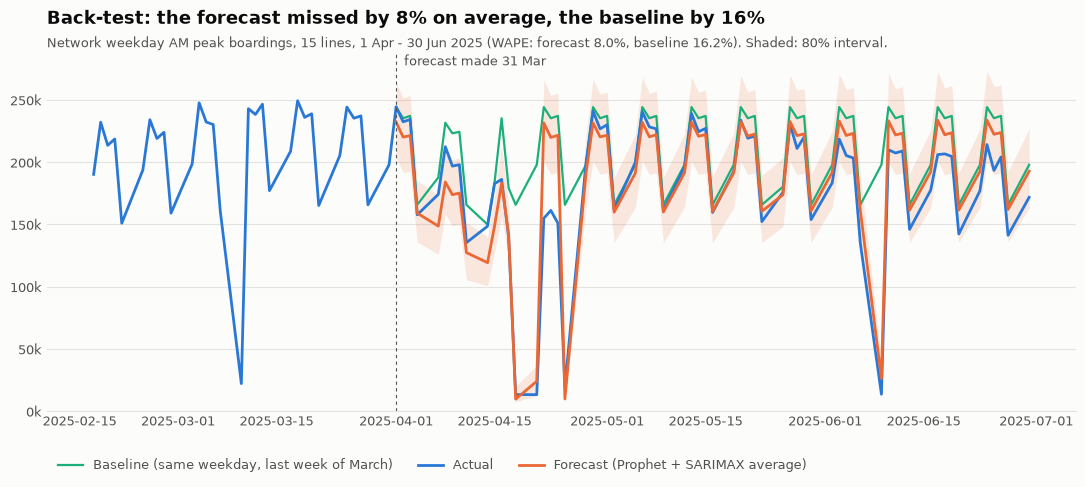

In [20]:
from pathlib import Path

IMAGES = Path("..") / "images"
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"


def style(ax, title, subtitle):
    ax.set_facecolor(SURFACE)
    ax.figure.set_facecolor(SURFACE)
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.spines["bottom"].set_color(GRID)
    ax.grid(axis="y", color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=INK_2, labelsize=9, length=0)
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}k")
    ax.set_title(title, loc="left", fontsize=13, color=INK, pad=22, fontweight="bold")
    ax.text(0, 1.02, subtitle, transform=ax.transAxes, fontsize=9.5, color=INK_2)
    ax.set_ylim(bottom=0)


# Chart 1: back-test
fig, ax = plt.subplots(figsize=(11, 5))
hist = data[data.ds.between(TRAIN_END - pd.Timedelta(weeks=6), TRAIN_END)].groupby("ds").actual.sum()
band = clean.groupby("ds")[["ensemble_lower", "ensemble_upper"]].sum()
ax.fill_between(band.index, band.ensemble_lower / 1e3, band.ensemble_upper / 1e3, color=ORANGE, alpha=0.14, lw=0)
ax.plot(net.index, net.seasonal_naive / 1e3, color=AQUA, lw=1.6, label="Baseline (same weekday, last week of March)")
ax.plot(pd.concat([hist, net.actual]).sort_index().index, pd.concat([hist, net.actual]).sort_index() / 1e3,
        color=BLUE, lw=2, label="Actual")
ax.plot(net.index, net.ensemble / 1e3, color=ORANGE, lw=2, label="Forecast (Prophet + SARIMAX average)")
ax.axvline(TEST_START, color=INK_2, lw=0.8, ls=(0, (3, 3)))
ax.text(TEST_START, 1.0, "  forecast made 31 Mar", color=INK_2, fontsize=9, va="top",
        transform=ax.get_xaxis_transform())
w = {k: score(net.assign(is_disrupted=False), {k: k}).loc[k, "WAPE %"] for k in ("ensemble", "seasonal_naive")}
style(ax, "Back-test: the forecast missed by 8% on average, the baseline by 16%",
      f"Network weekday AM peak boardings, 15 lines, 1 Apr - 30 Jun 2025 (WAPE: forecast {w['ensemble']:.1f}%, "
      f"baseline {w['seasonal_naive']:.1f}%). Shaded: 80% interval.")
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.1), frameon=False, fontsize=9, labelcolor=INK_2, ncol=3)
fig.tight_layout()
fig.savefig(IMAGES / "forecast_backtest.png", dpi=150, facecolor=SURFACE)
plt.show()

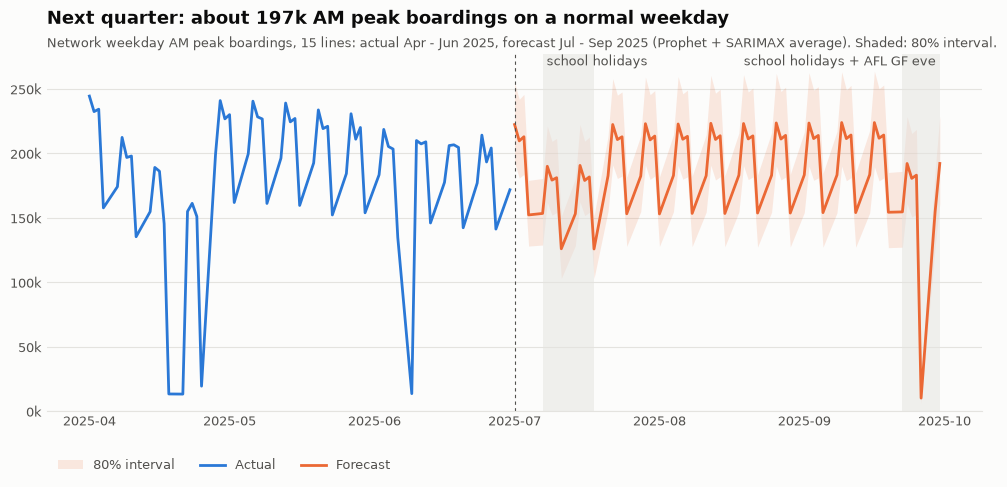

In [21]:
# Chart 2: forward forecast
recent = data[data.ds.between(pd.Timestamp("2025-04-01"), TEST_END)].groupby("ds").actual.sum()
fig, ax = plt.subplots(figsize=(11, 5))
ax.fill_between(net_fc.ds, net_fc.ensemble_lower / 1e3, net_fc.ensemble_upper / 1e3, color=ORANGE, alpha=0.14, lw=0,
                label="80% interval")
ax.plot(recent.index, recent / 1e3, color=BLUE, lw=2, label="Actual")
ax.plot(net_fc.ds, net_fc.ensemble / 1e3, color=ORANGE, lw=2, label="Forecast")
for start, end in (("2025-07-07", "2025-07-18"), ("2025-09-22", "2025-09-30")):
    ax.axvspan(pd.Timestamp(start), pd.Timestamp(end), color=GRID, alpha=0.5, lw=0)
ax.text(pd.Timestamp("2025-07-07"), 1.0, " school holidays", color=INK_2, fontsize=9, va="top",
        transform=ax.get_xaxis_transform())
ax.text(pd.Timestamp("2025-09-30"), 1.0, "school holidays + AFL GF eve ", color=INK_2, fontsize=9, va="top", ha="right",
        transform=ax.get_xaxis_transform())
ax.axvline(FC_START, color=INK_2, lw=0.8, ls=(0, (3, 3)))
nw = net_fc[net_fc.day_type == "Normal Weekday"].ensemble.mean()
style(ax, f"Next quarter: about {nw / 1e3:,.0f}k AM peak boardings on a normal weekday",
      "Network weekday AM peak boardings, 15 lines: actual Apr - Jun 2025, forecast Jul - Sep 2025 "
      "(Prophet + SARIMAX average). Shaded: 80% interval.")
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.1), frameon=False, fontsize=9, labelcolor=INK_2, ncol=3)
fig.tight_layout()
fig.savefig(IMAGES / "forecast_next_quarter.png", dpi=150, facecolor=SURFACE)
plt.show()

## 14. Write the results back to Snowflake

Three tables in `MART`, rebuilt on every run (`overwrite=True`). Power BI's forecast page reads them.

| Table | One row per | Contents |
|---|---|---|
| `FORECAST_LINE_DEMAND` | date × line × model | Jul–Sep 2025 forecast with 80% interval, for the ensemble and each model |
| `FORECAST_BACKTEST` | date × line × model | Apr–Jun 2025 actuals next to each model's back-test forecast |
| `FORECAST_METRICS` | model × line × day group | MAE, WAPE, MAPE on the test period, excluding disrupted days. Includes `All lines` and `Network` rows |

In [22]:
from snowflake.connector.pandas_tools import write_pandas

SELECTED = {"ensemble": "Ensemble (Prophet + SARIMAX)", "prophet_v1": "Prophet",
            "sarimax_v2": "SARIMAX", "seasonal_naive": "Baseline (seasonal naive)"}
CREATED_AT = pd.Timestamp.now().floor("s")


def to_long(frame, models, extra_cols):
    parts = []
    for col, label in models.items():
        part = frame[["ds", "line", "day_type", *extra_cols]].copy()
        part["model"] = label
        part["forecast"] = frame[col]
        part["lower_80"] = frame.get(f"{col}_lower", np.nan)
        part["upper_80"] = frame.get(f"{col}_upper", np.nan)
        parts.append(part)
    out = pd.concat(parts, ignore_index=True).rename(columns={"ds": "date", "line": "line_name"})
    out["date"] = out.date.dt.date
    out["created_at"] = CREATED_AT
    return out


forecast_table = to_long(forecast, {k: v for k, v in SELECTED.items() if k != "seasonal_naive"}, [])
backtest_table = to_long(backtest, SELECTED, ["actual", "is_disrupted"])

metric_rows = []
for group, frame in {"All days": clean, **{k: v for k, v in day_groups.items() if not k.startswith("All")}}.items():
    scopes = {line: g for line, g in frame.groupby("line")}
    scopes["All lines"] = frame
    scopes["Network"] = frame.groupby("ds")[["actual", *SELECTED]].sum()
    for scope, g in scopes.items():
        s = score(g, SELECTED)
        for label, r in s.iterrows():
            metric_rows.append({"model": label, "line_name": scope, "day_group": group, "mae": r["MAE"],
                                "wape_pct": r["WAPE %"], "mape_pct": r["MAPE %"], "line_days": int(r["line-days"])})
metrics_table = pd.DataFrame(metric_rows).assign(test_period="2025-04-01 to 2025-06-30", created_at=CREATED_AT)

with snowflake.connector.connect(connection_name="metro") as conn:
    for name, table in [("FORECAST_LINE_DEMAND", forecast_table), ("FORECAST_BACKTEST", backtest_table),
                        ("FORECAST_METRICS", metrics_table)]:
        t = table.rename(columns=str.upper)
        ok, _, nrows, _ = write_pandas(conn, t, name, schema="MART", auto_create_table=True,
                                       overwrite=True, use_logical_type=True)
        back = conn.cursor().execute(f"SELECT COUNT(*) FROM MART.{name}").fetchone()[0]
        print(f"MART.{name}: wrote {nrows:,} rows, table now has {back:,} -> {'OK' if ok and back == len(t) else 'CHECK'}")

MART.FORECAST_LINE_DEMAND: wrote 2,970 rows, table now has 2,970 -> OK


MART.FORECAST_BACKTEST: wrote 3,900 rows, table now has 3,900 -> OK


MART.FORECAST_METRICS: wrote 272 rows, table now has 272 -> OK


## 15. Check against what actually happened (Jul–Sep 2025)

The passenger-count data stops at June 2025: DataVic hadn't published FY2025-26 when this was written. But DTP's **official monthly patronage** (myki and barrier data, loaded as `STAGING.MONTHLY_PATRONAGE`) already covers Jul–Sep 2025, so the forecast can be checked against real outcomes at network level.

**The two measures differ** (AM peak boardings on 15 lines vs all-day station entries across the whole network), so they're compared as an **index: 100 = the April–June 2025 average**. The test is whether the forecast got the *change* into the next quarter right. Both sides are averaged the same way: per month and day of week first, then across the five weekdays (as in data quality check 8).

In [23]:
OFFICIAL_QUERY = '''
SELECT month_start, day_type, day_of_week, pax_daily
FROM STAGING.MONTHLY_PATRONAGE
WHERE mode = 'MetroTrain'
  AND day_type IN ('Normal Weekday', 'School Holiday Weekday')
  AND month_start BETWEEN '2024-04-01' AND '2025-09-01'
'''
with snowflake.connector.connect(connection_name="metro") as conn:
    official = conn.cursor().execute(OFFICIAL_QUERY).fetch_pandas_all().rename(columns=str.lower)
official["month_start"] = pd.to_datetime(official.month_start)
off = official.groupby(["month_start", "day_type"]).pax_daily.mean().unstack()


def monthly_index(daily, value, base_months):
    # Average per month x day of week, then across weekdays; index to the base months' average.
    d = daily.assign(month=daily.ds.dt.to_period("M").dt.to_timestamp(), dow=daily.ds.dt.dayofweek)
    m = d.groupby(["month", "dow"])[value].mean().groupby("month").mean()
    return m, 100 * m / m.loc[base_months].mean()


base_2025 = pd.date_range("2025-04-01", "2025-06-01", freq="MS")
ours_daily = pd.concat([
    data[(data.day_type == "Normal Weekday") & data.ds.between(TEST_START, TEST_END)]
        .groupby("ds").actual.sum().rename("value").reset_index(),
    net_fc[net_fc.day_type == "Normal Weekday"][["ds", "ensemble"]].rename(columns={"ensemble": "value"}),
])
ours_level, ours_idx = monthly_index(ours_daily, "value", base_2025)
off_nw = off["Normal Weekday"]
off_idx = 100 * off_nw / off_nw.loc[base_2025].mean()

check = pd.DataFrame({
    "source": ["actual"] * 3 + ["forecast"] * 3,
    "ours (AM peak, 15 lines)": ours_level.values,
    "ours index": ours_idx.values,
    "official (all day)": off_nw.loc[ours_level.index].values,
    "official index": off_idx.loc[ours_level.index].values,
}, index=ours_level.index.strftime("%b %Y"))
check["gap (points)"] = check["ours index"] - check["official index"]
print("Normal weekdays. Index: 100 = Apr-Jun 2025 average")
check.round(1)

Normal weekdays. Index: 100 = Apr-Jun 2025 average


,source,"ours (AM peak, 15 lines)",ours index,official (all day),official index,gap (points)
month,,,,,,
Apr 2025,actual,"193,897.0",98.9,"609,930.0",102.5,-3.6
May 2025,actual,"206,430.4",105.3,"624,560.0",105.0,0.3
Jun 2025,actual,"187,721.0",95.8,"550,090.0",92.5,3.3
Jul 2025,forecast,"196,121.6",100.1,"572,290.0",96.2,3.8
Aug 2025,forecast,"196,733.2",100.4,"597,480.0",100.4,-0.1
Sep 2025,forecast,"197,289.2",100.6,"572,150.0",96.2,4.5


In [24]:
# How does Jul-Sep normally compare with Apr-Jun? The same index for 2024 (official data).
base_2024 = pd.date_range("2024-04-01", "2024-06-01", freq="MS")
idx_2024 = 100 * off_nw / off_nw.loc[base_2024].mean()
season = pd.DataFrame({
    "2024 official": idx_2024.loc[pd.date_range("2024-07-01", "2024-09-01", freq="MS")].values,
    "2025 official": off_idx.loc[pd.date_range("2025-07-01", "2025-09-01", freq="MS")].values,
    "2025 forecast": ours_idx.loc[pd.date_range("2025-07-01", "2025-09-01", freq="MS")].values,
}, index=["Jul", "Aug", "Sep"])
season.loc["Jul-Sep avg"] = season.mean()
print("Jul-Sep vs Apr-Jun of the same year (index, Apr-Jun = 100), normal weekdays")
season.round(1)

Jul-Sep vs Apr-Jun of the same year (index, Apr-Jun = 100), normal weekdays


,2024 official,2025 official,2025 forecast
Jul,96.9,96.2,100.1
Aug,102.7,100.4,100.4
Sep,99.7,96.2,100.6
Jul-Sep avg,99.8,97.6,100.4


In [25]:
# School holiday weekdays (July break): level relative to Apr-Jun normal weekdays
sh_fc = net_fc[(net_fc.day_type == "School Holiday") & (net_fc.ds.dt.month == 7)].ensemble.mean()
sh_ratio_fc = 100 * sh_fc / ours_level.loc[base_2025].mean()
sh_ratio_off = 100 * off.loc[pd.Timestamp("2025-07-01"), "School Holiday Weekday"] / off_nw.loc[base_2025].mean()
print(f"July 2025 school holiday weekdays, as % of an Apr-Jun normal weekday: "
      f"forecast {sh_ratio_fc:.1f}%, official {sh_ratio_off:.1f}%")

July 2025 school holiday weekdays, as % of an Apr-Jun normal weekday: forecast 84.6%, official 81.7%


## 16. Conclusions

The numbers quoted in `docs/forecast_results.md` come from the cells above.

- **The forecast beats the baseline.**
  - Over the 13-week back-test, the ensemble missed by **8.0%** at network level (WAPE), against **16.2%** for the seasonal naive baseline. Across all line-days it was 10.5% against 18.3%.
  - It beat the baseline on **14 of 15 lines**. The exception is Hurstbridge (18.1% vs 17.6%), after its unexplained level shift.
  - Its 80% interval held 79% of actual values, so it is well calibrated.
- **Holidays are where the models earn their keep.** On normal weekdays the ensemble is moderately better than "same as last week" (9.8% vs 12.3% WAPE). Most of the gain is on school and public holidays, which the baseline can't anticipate.
- **Two choices were made before seeing the test results, and both held up:**
  - a conservative trend, so the March peak isn't carried forward;
  - a validation check, which rejected Prophet v2's log scale before it reached the test.
- **Checked against what actually happened** (official patronage, Jul–Sep 2025):
  - The forecast expected a **flat** quarter: index 100.4 against Apr–Jun = 100.
  - Official patronage dipped slightly, to **97.6**. So the forecast ran about 3 points high, mostly in July and September.
  - That's about the same size as the gap between the two measures in months where both are actuals (−3.6 to +3.3 points). The forecast is consistent with the outcome, but it can't anticipate the seasonal dips, because it has no yearly pattern.
  - July school holidays: forecast at 84.6% of a normal weekday, against 81.7% officially.
- **Limitations:**
  - One year of data, so no yearly pattern can be learned.
  - The data comes from before the Metro Tunnel opened.
  - Prophet's own intervals are too narrow (58% coverage).
  - All public holidays share one effect, so the AFL Grand Final eve (26.9k AM peak in 2024) is likely under-forecast at about 10k.
  - Hurstbridge is under-forecast after its level shift.
  - Unusual weeks with no precedent in training, like the Easter–ANZAC working days, are missed.
- **Next step:** add the FY2023-24 passenger counts, which DataVic publishes back to FY2018-19. A second year would let every public holiday have its own effect and let the model learn the yearly pattern (the March peak, the winter dip).